# 01. EDA · 전처리 · 모델링 (LightGBM / RandomForest)

- 원본 데이터 탐색(결측치, 클래스 비율, 상관관계, 이상치) → 12단계 전처리·피처 엔지니어링 → 5-Fold Stratified CV로 LightGBM·RandomForest 비교
- 이 노트북은 EDA 기반 파생 피처와 상호작용 키까지 모두 넣은 **확장 피처(121개) 실험 버전**입니다. 최종 제출 모델(Baseline LightGBM, 40개 피처)과의 비교는 README 참고
- 데이터는 `../data/`에 `train.csv`, `test.csv` 배치


## 기본 세팅

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

# 시드 고정
SEED = 42
np.random.seed(SEED)

print('라이브러리 로드 완료')

라이브러리 로드 완료


In [ ]:
from pathlib import Path

DATA_DIR = Path("../data")

print(DATA_DIR.exists())
list(DATA_DIR.glob('*'))


In [58]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')

print(f'train shape: {train.shape}')
print(f'test shape : {test.shape}')

train.head(3)


train shape: (144415, 26)
test shape : (36104, 25)


,id,Type,Late_delivery_risk,Category Name,Customer City,Customer Country,Customer Segment,Customer State,Department Name,Latitude,...,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Product Name,Product Price
0,126637,PAYMENT,1,Women's Apparel,Caguas,Puerto Rico,Consumer,PR,Golf,18.280005,...,0.00,0.47,1,50.000000,50.000000,23.500000,Western Europe,Renania del Norte-Westfalia,Nike Men's Dri-FIT Victory Golf Polo,50.000000
1,120898,TRANSFER,0,Men's Footwear,Marietta,EE. UU.,Consumer,GA,Apparel,34.020615,...,0.25,0.36,1,129.990005,97.489998,35.389999,Southern Europe,Toscana,Nike Men's CJ Elite 2 TD Football Cleat,129.990005
2,68770,PAYMENT,1,Cleats,Caguas,Puerto Rico,Corporate,PR,Apparel,18.235752,...,0.20,0.45,2,119.980003,95.980003,43.189999,Western Europe,Baja Sajonia,Perfect Fitness Perfect Rip Deck,59.990002


In [59]:
df = train.copy()

print(df.shape)
df.describe().T


(144415, 26)


,count,mean,std,min,25%,50%,75%,max
id,144415.0,90364.661732,52070.134045,0.000000,45321.000000,90395.000000,135477.000000,180518.000000
Late_delivery_risk,144415.0,0.548288,0.497665,0.000000,0.000000,1.000000,1.000000,1.000000
Latitude,144415.0,29.728549,9.817374,-33.937553,18.265431,33.144863,39.285141,48.781933
Longitude,144415.0,-84.907291,21.467567,-158.025986,-98.464638,-76.777069,-66.370583,115.263077
Order Item Discount,144415.0,20.671476,21.854653,0.000000,5.400000,14.000000,30.000000,500.000000
Order Item Discount Rate,144415.0,0.101762,0.070566,0.000000,0.040000,0.100000,0.160000,0.250000
Order Item Profit Ratio,144415.0,0.120748,0.466909,-2.750000,0.080000,0.270000,0.360000,0.500000
Order Item Quantity,144415.0,2.129045,1.453546,1.000000,1.000000,1.000000,3.000000,5.000000
Sales,144415.0,203.716822,131.985498,9.990000,119.980003,199.919998,299.950012,1999.989990
Order Item Total,144415.0,183.045600,119.735836,7.490000,104.379997,163.990005,247.399994,1939.989990


In [60]:
# 숫자형 / 문자형 변수 요약 한 번에 보기

num_desc = df.describe().T
num_desc['dtype'] = df[num_desc.index].dtypes
num_desc['missing'] = df[num_desc.index].isnull().sum()
num_desc['n_unique'] = df[num_desc.index].nunique()
num_desc = num_desc[
    ['dtype', 'missing', 'n_unique', 'count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
]

object_cols = df.select_dtypes(include='object').columns

cat_desc = pd.DataFrame({
    'dtype': df[object_cols].dtypes,
    'missing': df[object_cols].isnull().sum(),
    'n_unique': df[object_cols].nunique(),
    'most_common': df[object_cols].mode().iloc[0],
    'most_common_count': [
        df[col].value_counts(dropna=False).iloc[0] for col in object_cols
    ],
    'most_common_ratio': [
        df[col].value_counts(dropna=False).iloc[0] / len(df) for col in object_cols
    ]
})

display(num_desc)
display(cat_desc.sort_values('n_unique', ascending=False))


,dtype,missing,n_unique,count,mean,std,min,25%,50%,75%,max
id,int64,0,144415,144415.0,90364.661732,52070.134045,0.000000,45321.000000,90395.000000,135477.000000,180518.000000
Late_delivery_risk,int64,0,2,144415.0,0.548288,0.497665,0.000000,0.000000,1.000000,1.000000,1.000000
Latitude,float64,0,10663,144415.0,29.728549,9.817374,-33.937553,18.265431,33.144863,39.285141,48.781933
Longitude,float64,0,4471,144415.0,-84.907291,21.467567,-158.025986,-98.464638,-76.777069,-66.370583,115.263077
Order Item Discount,float64,0,993,144415.0,20.671476,21.854653,0.000000,5.400000,14.000000,30.000000,500.000000
Order Item Discount Rate,float64,0,18,144415.0,0.101762,0.070566,0.000000,0.040000,0.100000,0.160000,0.250000
Order Item Profit Ratio,float64,0,162,144415.0,0.120748,0.466909,-2.750000,0.080000,0.270000,0.360000,0.500000
Order Item Quantity,int64,0,5,144415.0,2.129045,1.453546,1.000000,1.000000,1.000000,3.000000,5.000000
Sales,float64,0,193,144415.0,203.716822,131.985498,9.990000,119.980003,199.919998,299.950012,1999.989990
Order Item Total,float64,0,2843,144415.0,183.045600,119.735836,7.490000,104.379997,163.990005,247.399994,1939.989990


,dtype,missing,n_unique,most_common,most_common_count,most_common_ratio
order date (DateOrders),object,0,61129,1/1/2015 19:58,5,0.000035
Order City,object,0,3581,New York City,1756,0.012159
Order State,object,0,1086,Inglaterra,5396,0.037365
Customer City,object,0,563,Caguas,53412,0.369851
Order Country,object,0,164,Estados Unidos,19912,0.137880
Product Name,object,0,118,Perfect Fitness Perfect Rip Deck,19706,0.136454
Category Name,object,0,50,Cleats,19732,0.136634
Customer State,object,0,46,PR,55479,0.384164
Order Region,object,0,23,Central America,22695,0.157151
Department Name,object,0,11,Fan Shop,53438,0.370031


In [61]:
# 문자형 변수별 상위 10개 값 분포

for col in object_cols:
    print(f'\n[{col}]')
    display(df[col].value_counts(dropna=False).head(10).to_frame('count'))



[Type]


,count
Type,
DEBIT,55419
TRANSFER,39961
PAYMENT,33406
CASH,15629



[Category Name]


,count
Category Name,
Cleats,19732
Men's Footwear,17747
Women's Apparel,16876
Indoor/Outdoor Games,15425
Fishing,13840
Water Sports,12449
Camping & Hiking,10954
Cardio Equipment,10025
Shop By Sport,8744



[Customer City]


,count
Customer City,
Caguas,53412
Chicago,3118
Brooklyn,2735
Los Angeles,2735
New York,1480
Philadelphia,1292
Bronx,1179
San Diego,1158
Houston,1044


... (18 outputs left out)


[Order State]


,count
Order State,
Inglaterra,5396
California,4005
Isla de Francia,3690
Renania del Norte-Westfalia,2638
San Salvador,2475
Nueva York,2209
Distrito Federal,2047
Texas,1971
Nueva Gales del Sur,1893



[Product Name]


,count
Product Name,
Perfect Fitness Perfect Rip Deck,19706
Nike Men's CJ Elite 2 TD Football Cleat,17747
Nike Men's Dri-FIT Victory Golf Polo,16876
O'Brien Men's Neoprene Life Vest,15425
Field & Stream Sportsman 16 Gun Fire Safe,13840
Pelican Sunstream 100 Kayak,12417
Diamondback Women's Serene Classic Comfort Bi,10954
Nike Men's Free 5.0+ Running Shoe,9759
Under Armour Girls' Toddler Spine Surge Runni,8465


### 결측치

In [62]:
# 결측치 확인

missing_df = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_ratio': df.isnull().mean()
})

missing_df = missing_df[missing_df['missing_count'] > 0]
missing_df = missing_df.sort_values('missing_count', ascending=False)

print("결측치 있는 컬럼 수:", len(missing_df))
display(missing_df)


결측치 있는 컬럼 수: 0


,missing_count,missing_ratio


### 클래스 불균형

,count,ratio
Late_delivery_risk,,
0,65234,0.451712
1,79181,0.548288


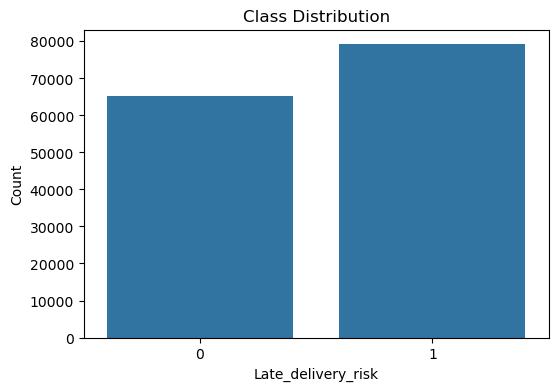

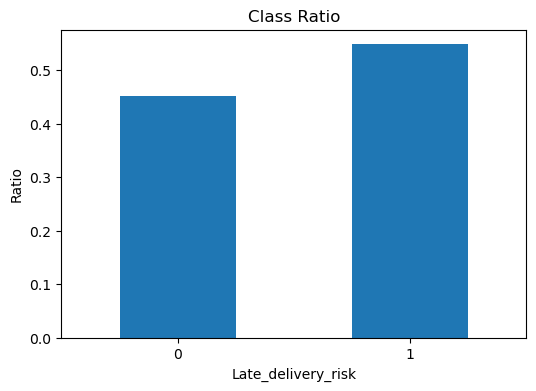

Late_delivery_risk
0    45.17%
1    54.83%
Name: proportion, dtype: object

In [63]:
# 클래스 불균형 확인

target = 'Late_delivery_risk'

class_count = df[target].value_counts().sort_index()
class_ratio = df[target].value_counts(normalize=True).sort_index()

class_balance = pd.DataFrame({
    'count': class_count,
    'ratio': class_ratio
})

display(class_balance)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title('Class Distribution')
plt.xlabel(target)
plt.ylabel('Count')
plt.show()

plt.figure(figsize=(6, 4))
class_ratio.plot(kind='bar')
plt.title('Class Ratio')
plt.xlabel(target)
plt.ylabel('Ratio')
plt.xticks(rotation=0)
plt.show()

(class_ratio * 100).round(2).astype(str) + '%'


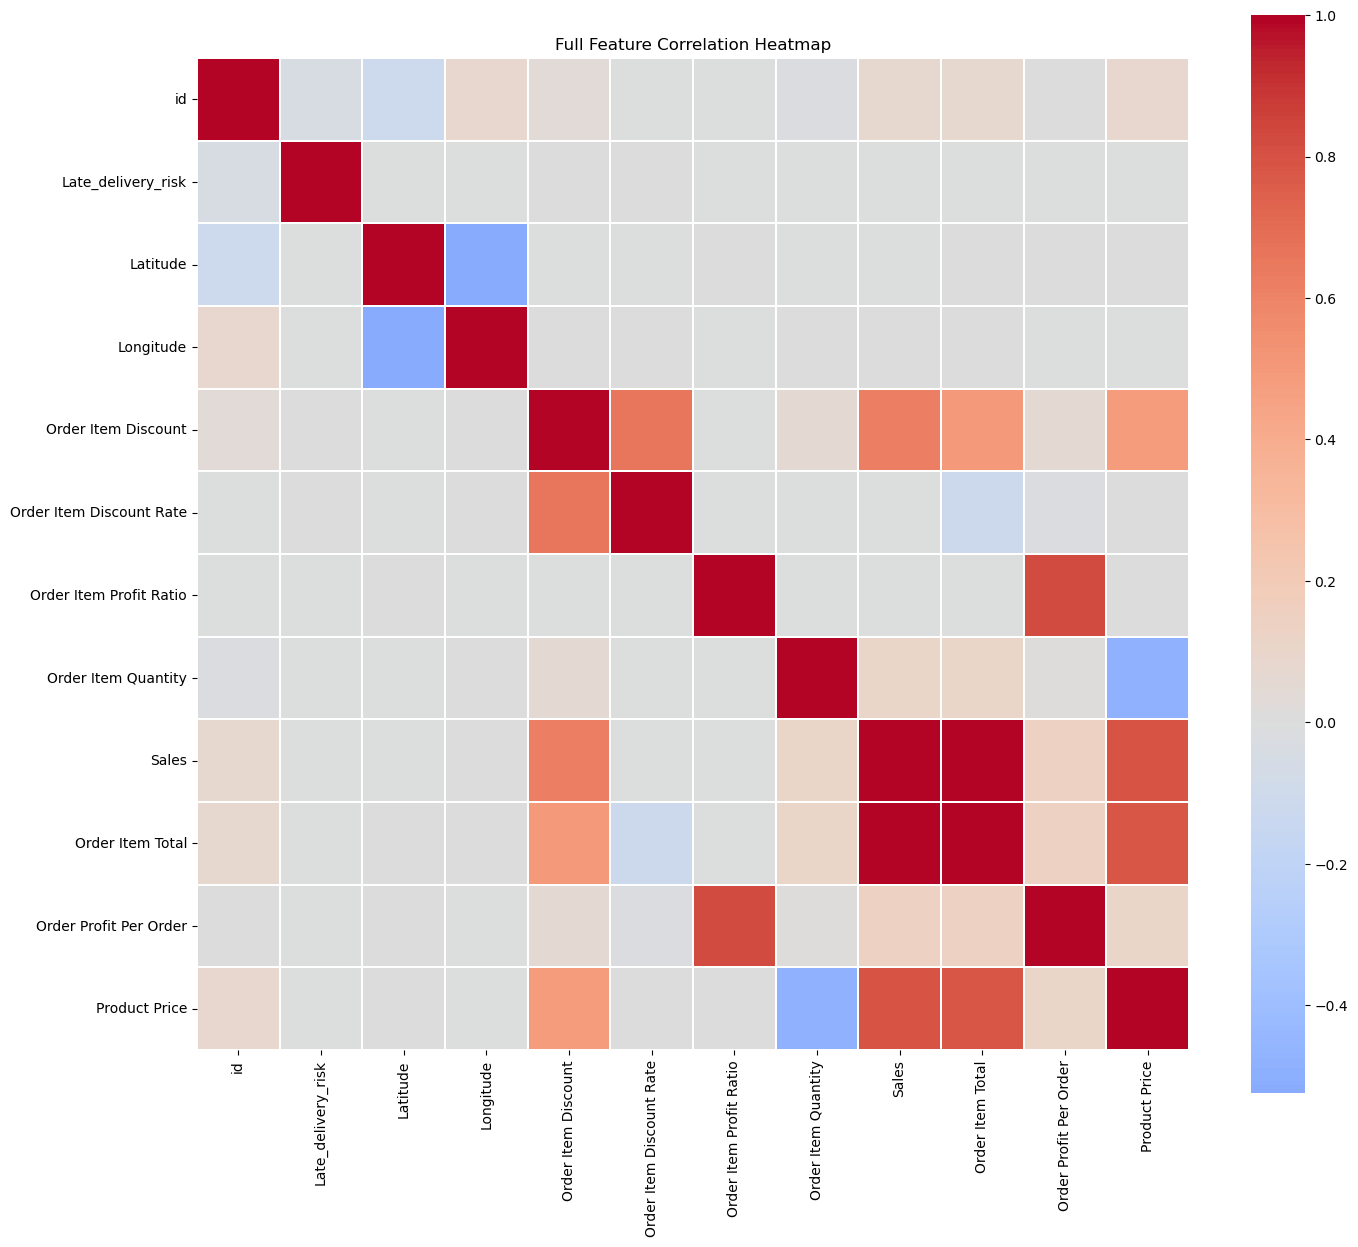

전체 feature pair 개수: 66


,feature_1,feature_2,correlation
0,Sales,Order Item Total,0.989637
1,Order Item Profit Ratio,Order Profit Per Order,0.822271
2,Sales,Product Price,0.789024
3,Order Item Total,Product Price,0.780642
4,Order Item Discount,Order Item Discount Rate,0.659567
5,Order Item Discount,Sales,0.617289
6,Latitude,Longitude,0.524296
7,Order Item Discount,Order Item Total,0.497921
8,Order Item Discount,Product Price,0.488183
9,Order Item Quantity,Product Price,0.476820


In [64]:
# Feature 간 상관 분석 for 다중공선성 확인 - 전체 출력

# 1. 상관계수 계산
corr = df.corr(numeric_only=True)

# 2. 전체 히트맵
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    annot=False,
    square=True,
    linewidths=0.3
)
plt.title('Full Feature Correlation Heatmap')
plt.show()

# 3. 상관 쌍 전체 추출 (중복 제거)
corr_abs = corr.abs()
upper = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

corr_pairs = (
    upper.stack()
    .sort_values(ascending=False)
    .reset_index()
)

corr_pairs.columns = ['feature_1', 'feature_2', 'correlation']

# 4. 전체 출력
print(f"전체 feature pair 개수: {len(corr_pairs)}")

pd.set_option('display.max_rows', None)
display(corr_pairs)
pd.reset_option('display.max_rows')



,correlation_with_target
id,-0.046589
Order Profit Per Order,-0.003924
Order Item Total,-0.003034
Sales,-0.002773
Order Item Profit Ratio,-0.002263
Product Price,-0.001242
Longitude,-0.000936
Order Item Quantity,-0.000746
Order Item Discount Rate,0.000569
Latitude,-0.000384


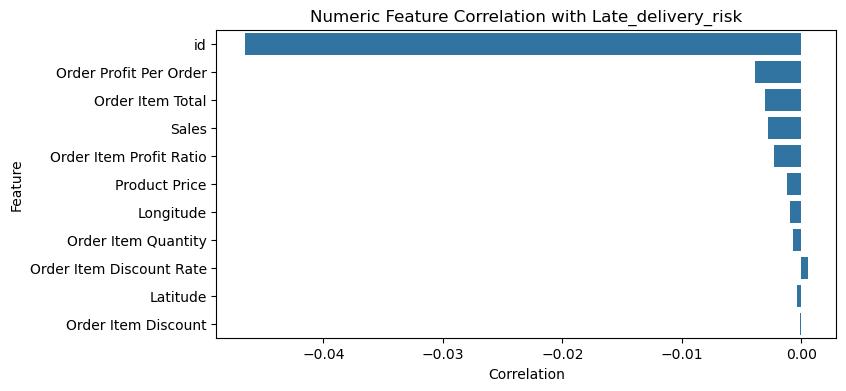

In [65]:
# 1. 숫자형 feature와 타깃(Late_delivery_risk)의 상관관계

target = 'Late_delivery_risk'

num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols = [col for col in num_cols if col != target]

target_corr = (
    df[num_cols + [target]]
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(key=lambda x: x.abs(), ascending=False)
    .to_frame('correlation_with_target')
)

display(target_corr)

plt.figure(figsize=(8, max(4, len(target_corr) * 0.35)))
sns.barplot(
    data=target_corr.reset_index(),
    x='correlation_with_target',
    y='index'
)
plt.title('Numeric Feature Correlation with Late_delivery_risk')
plt.xlabel('Correlation')
plt.ylabel('Feature')
plt.show()


In [66]:
# 2. 범주형 feature별 Late_delivery_risk 평균 차이 보기

cat_cols = df.select_dtypes(include='object').columns.tolist()

cat_target_summary = []

for col in cat_cols:
    tmp = df.groupby(col)[target].agg(['mean', 'count']).reset_index()
    
    # 너무 적은 샘플 카테고리는 제외
    tmp = tmp[tmp['count'] >= 100]
    
    if len(tmp) == 0:
        continue
    
    max_mean = tmp['mean'].max()
    min_mean = tmp['mean'].min()
    
    cat_target_summary.append({
        'feature': col,
        'n_unique': df[col].nunique(),
        'max_late_rate': max_mean,
        'min_late_rate': min_mean,
        'late_rate_gap': max_mean - min_mean
    })

cat_target_summary = (
    pd.DataFrame(cat_target_summary)
    .sort_values('late_rate_gap', ascending=False)
)

display(cat_target_summary)


,feature,n_unique,max_late_rate,min_late_rate,late_rate_gap
8,Order City,3581,0.724409,0.310000,0.414409
11,Order State,1086,0.740000,0.330508,0.409492
2,Customer City,563,0.741379,0.374408,0.366972
9,Order Country,164,0.655022,0.380000,0.275022
12,Product Name,118,0.620690,0.487805,0.132885
1,Category Name,50,0.591753,0.487069,0.104684
0,Type,4,0.575855,0.485098,0.090757
5,Customer State,46,0.599490,0.511536,0.087954
10,Order Region,23,0.572924,0.492903,0.080021
6,Department Name,11,0.574803,0.545468,0.029335


### 히스토그램

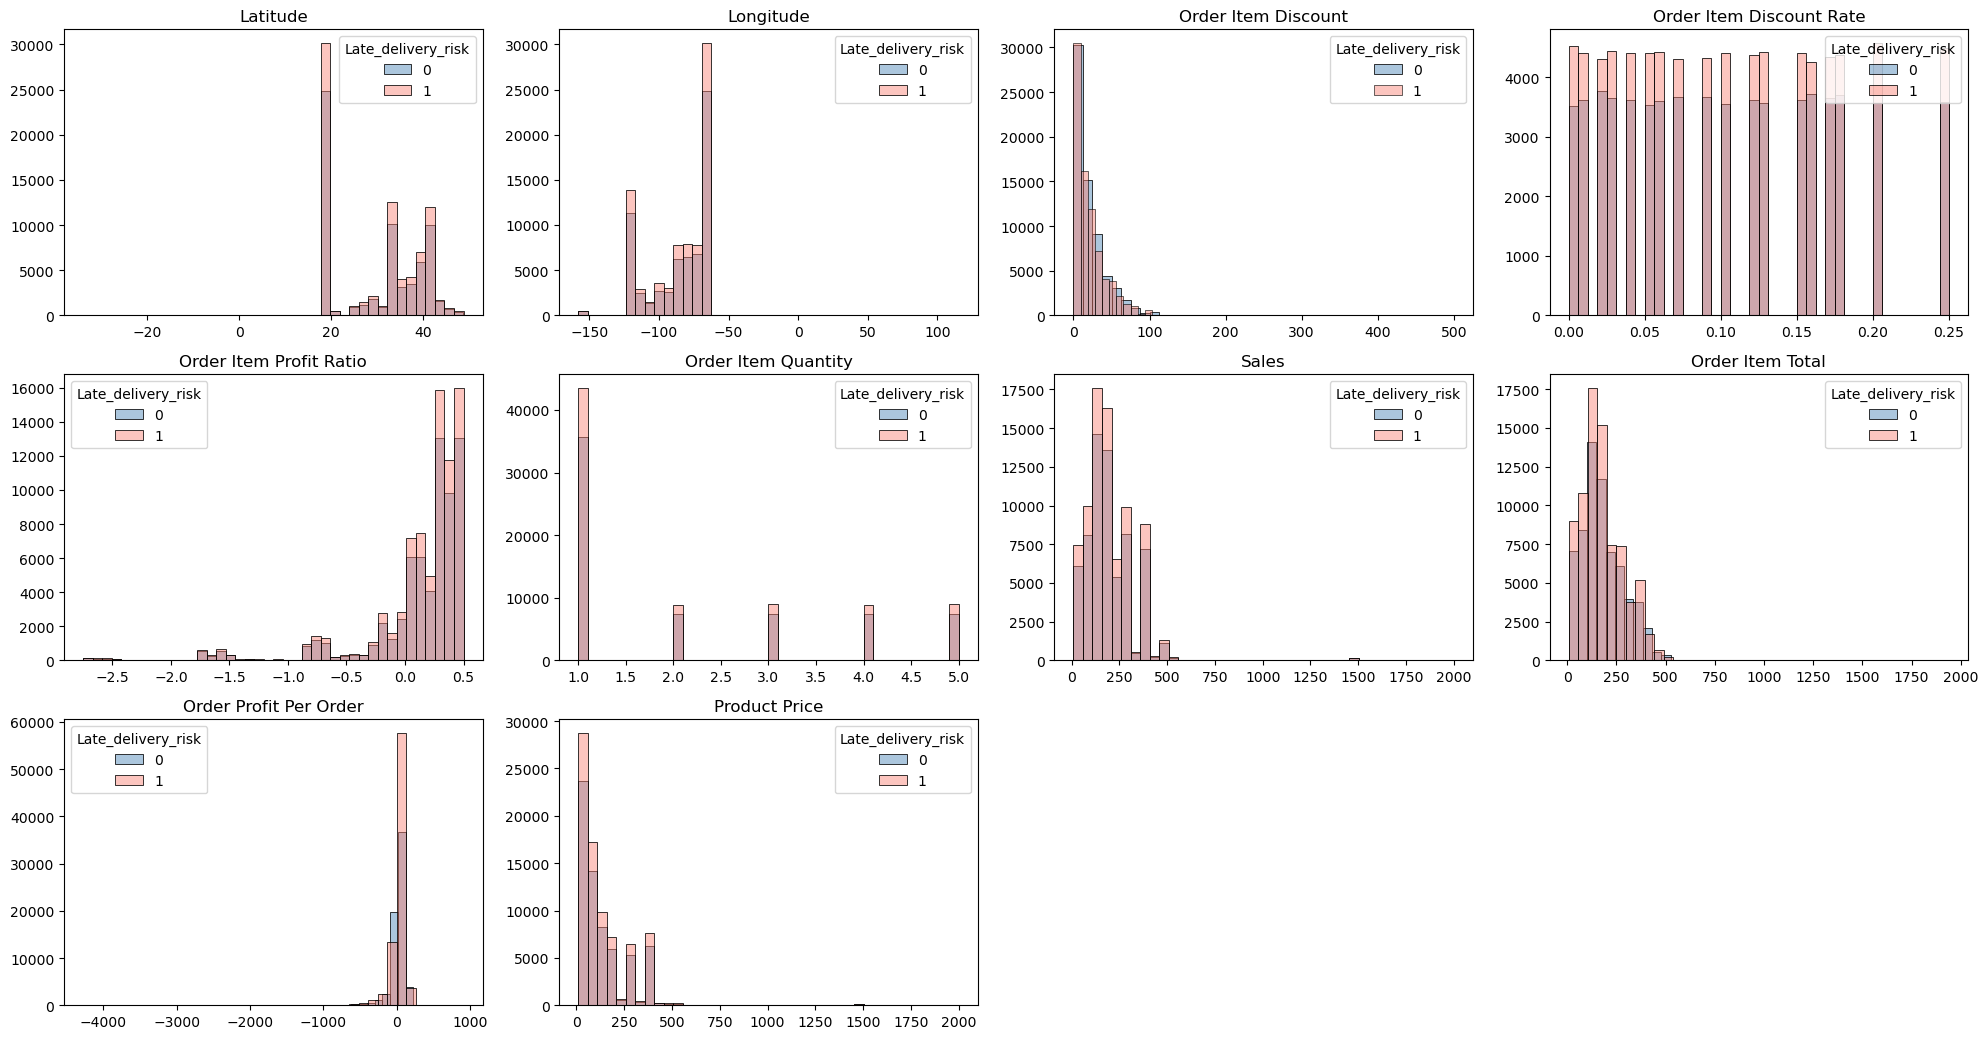

In [67]:
# 수치형 변수 분포 비교: Late_delivery_risk 0 vs 1

target = 'Late_delivery_risk'

num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols = [col for col in num_cols if col not in [target, 'id']]

n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))

plt.figure(figsize=(5 * n_cols, 3.5 * n_rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    
    sns.histplot(
        df[df[target] == 0][col],
        bins=40,
        color='steelblue',
        alpha=0.45,
        label='0',
        stat='count'
    )
    
    sns.histplot(
        df[df[target] == 1][col],
        bins=40,
        color='salmon',
        alpha=0.45,
        label='1',
        stat='count'
    )
    
    plt.title(col)
    plt.legend(title=target)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()


In [68]:
# IQR 기반 이상치 분석

target = 'Late_delivery_risk'

num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols = [col for col in num_cols if col not in [target, 'id']]

outlier_summary = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    outlier_count = outlier_mask.sum()
    outlier_ratio = outlier_count / len(df)
    
    outlier_summary.append({
        'feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outlier_count': outlier_count,
        'outlier_ratio': outlier_ratio
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary = outlier_summary.sort_values('outlier_ratio', ascending=False)

display(outlier_summary)


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_ratio
8,Order Profit Per Order,7.040000,64.790001,57.750001,-79.585001,151.415002,15101,0.104567
4,Order Item Profit Ratio,0.080000,0.360000,0.280000,-0.340000,0.780000,13812,0.095641
2,Order Item Discount,5.400000,30.000000,24.600000,-31.500000,66.900000,6057,0.041942
9,Product Price,50.000000,199.990005,149.990005,-174.985008,424.975014,1645,0.011391
7,Order Item Total,104.379997,247.399994,143.019997,-110.149998,461.929989,1548,0.010719
1,Longitude,-98.464638,-66.370583,32.094055,-146.605721,-18.229500,1131,0.007832
6,Sales,119.980003,299.950012,179.970009,-149.975010,569.905025,385,0.002666
0,Latitude,18.265431,39.285141,21.019710,-13.264133,70.814705,8,0.000055
3,Order Item Discount Rate,0.040000,0.160000,0.120000,-0.140000,0.340000,0,0.000000
5,Order Item Quantity,1.000000,3.000000,2.000000,-2.000000,6.000000,0,0.000000


In [69]:
# 타겟 변수와의 상관계수 전체 출력

target = 'Late_delivery_risk'

target_corr = (
    df.corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(key=lambda x: x.abs(), ascending=False)
    .to_frame('correlation_with_target')
)

target_corr['abs_correlation'] = target_corr['correlation_with_target'].abs()

display(target_corr)


,correlation_with_target,abs_correlation
id,-0.046589,0.046589
Order Profit Per Order,-0.003924,0.003924
Order Item Total,-0.003034,0.003034
Sales,-0.002773,0.002773
Order Item Profit Ratio,-0.002263,0.002263
Product Price,-0.001242,0.001242
Longitude,-0.000936,0.000936
Order Item Quantity,-0.000746,0.000746
Order Item Discount Rate,0.000569,0.000569
Latitude,-0.000384,0.000384


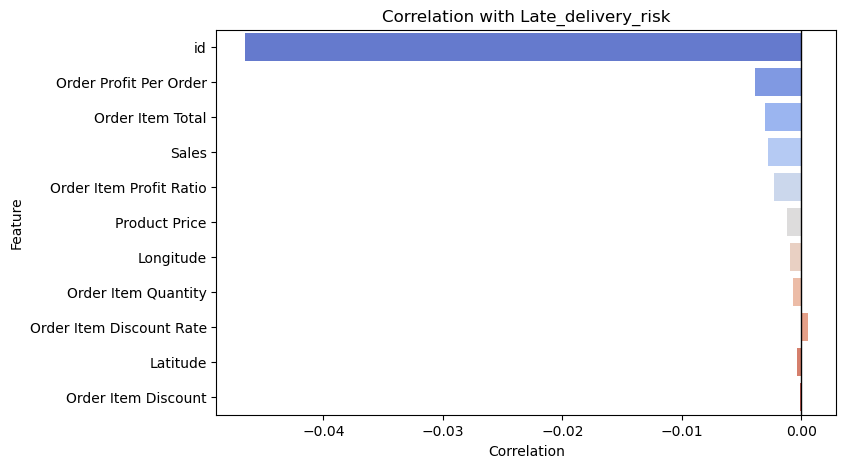

In [70]:
# 타겟 변수와의 상관계수 시각화

plt.figure(figsize=(8, max(5, len(target_corr) * 0.45)))
sns.barplot(
    data=target_corr.reset_index(),
    x='correlation_with_target',
    y='index',
    palette='coolwarm'
)
plt.axvline(0, color='black', linewidth=1)
plt.title('Correlation with Late_delivery_risk')
plt.xlabel('Correlation')
plt.ylabel('Feature')
plt.show()



In [71]:
# Type별 Late_delivery_risk 0/1 비율 차이

target = 'Late_delivery_risk'
type_col = 'Type'

type_target = pd.crosstab(
    df[type_col],
    df[target],
    normalize='index'
)

type_count = pd.crosstab(
    df[type_col],
    df[target]
)

type_summary = pd.concat(
    [
        type_count.add_prefix('count_'),
        type_target.add_prefix('ratio_')
    ],
    axis=1
)

type_summary['ratio_gap_1_minus_0'] = type_summary['ratio_1'] - type_summary['ratio_0']
type_summary = type_summary.sort_values('ratio_1', ascending=False)

display(type_summary)


Late_delivery_risk,count_0,count_1,ratio_0,ratio_1,ratio_gap_1_minus_0
Type,,,,,
PAYMENT,14169,19237,0.424145,0.575855,0.151709
DEBIT,23696,31723,0.427579,0.572421,0.144842
CASH,6793,8836,0.434641,0.565359,0.130719
TRANSFER,20576,19385,0.514902,0.485098,-0.029804


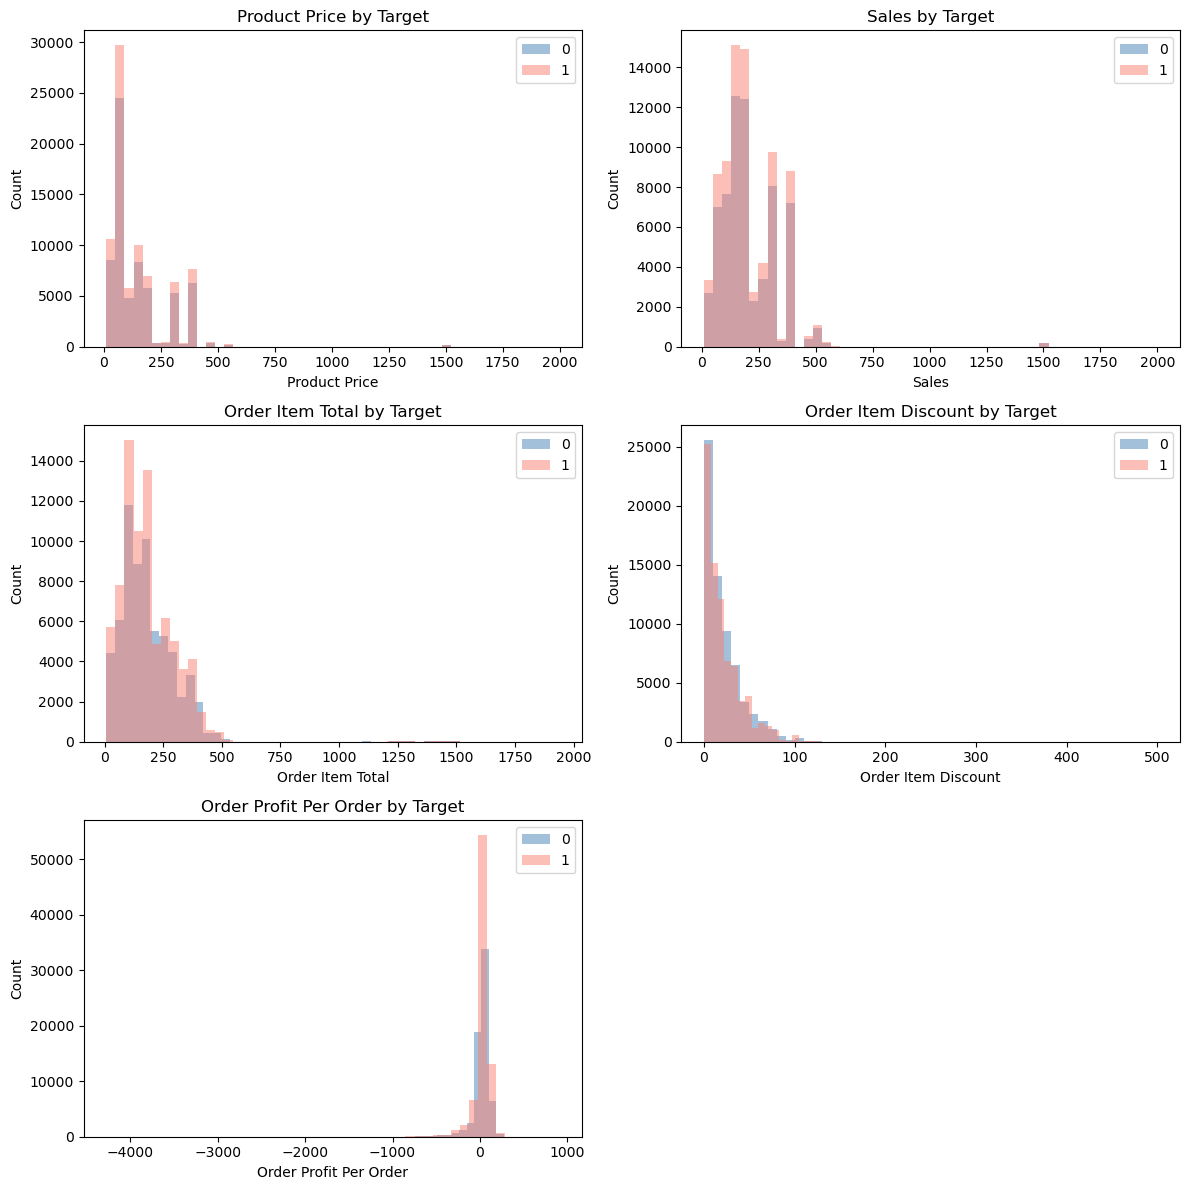

In [72]:
# 가격 관련 변수 히스토그램: Late_delivery_risk 0 vs 1

target = 'Late_delivery_risk'

price_cols = [
    'Product Price',
    'Sales',
    'Order Item Total',
    'Order Item Discount',
    'Order Profit Per Order'
]

price_cols = [col for col in price_cols if col in df.columns]

n_cols = 2
n_rows = int(np.ceil(len(price_cols) / n_cols))

plt.figure(figsize=(12, 4 * n_rows))

for i, col in enumerate(price_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    
    plt.hist(
        df.loc[df[target] == 0, col].dropna(),
        bins=50,
        alpha=0.5,
        label='0',
        color='steelblue'
    )
    
    plt.hist(
        df.loc[df[target] == 1, col].dropna(),
        bins=50,
        alpha=0.5,
        label='1',
        color='salmon'
    )
    
    plt.title(f'{col} by Target')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.legend()

plt.tight_layout()
plt.show()


# 전처리

## 전처리 전략

In [73]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")


TARGET = "Late_delivery_risk"

train = train.copy()
test = test.copy()

# id 컬럼명 깨짐 방지
train.columns = train.columns.str.replace("\ufeff", "", regex=False)
test.columns = test.columns.str.replace("\ufeff", "", regex=False)

test_id = test["id"].copy()

# ── 1. 드롭 ──
DROP_COLS = ["id", "Sales"]

train = train.drop(columns=DROP_COLS)
test = test.drop(columns=[c for c in DROP_COLS if c in test.columns])

# ── 2. Customer State 정제 ──
STATE_MAP = {
    "AL":"Alabama","AK":"Alaska","AZ":"Arizona","AR":"Arkansas","CA":"California",
    "CO":"Colorado","CT":"Connecticut","DE":"Delaware","DC":"District of Columbia",
    "FL":"Florida","GA":"Georgia","HI":"Hawaii","ID":"Idaho","IL":"Illinois",
    "IN":"Indiana","IA":"Iowa","KS":"Kansas","KY":"Kentucky","LA":"Louisiana",
    "ME":"Maine","MD":"Maryland","MA":"Massachusetts","MI":"Michigan","MN":"Minnesota",
    "MS":"Mississippi","MO":"Missouri","MT":"Montana","NE":"Nebraska","NV":"Nevada",
    "NH":"New Hampshire","NJ":"New Jersey","NM":"New Mexico","NY":"New York",
    "NC":"North Carolina","ND":"North Dakota","OH":"Ohio","OK":"Oklahoma","OR":"Oregon",
    "PA":"Pennsylvania","RI":"Rhode Island","SC":"South Carolina","SD":"South Dakota",
    "TN":"Tennessee","TX":"Texas","UT":"Utah","VT":"Vermont","VA":"Virginia",
    "WA":"Washington","WV":"West Virginia","WI":"Wisconsin","WY":"Wyoming","PR":"Puerto Rico"
}

def clean_customer_state(df):
    df = df.copy()
    df["Customer State"] = df["Customer State"].astype(str)

    mask = df["Customer State"].str.match(r"^\d", na=False)
    df.loc[mask, "Customer State"] = np.nan

    mode_val = df["Customer State"].mode()[0]
    df["Customer State"] = df["Customer State"].fillna(mode_val)
    df["Customer State"] = df["Customer State"].map(STATE_MAP).fillna(df["Customer State"])

    return df

train = clean_customer_state(train)
test = clean_customer_state(test)

print(f"Customer State 정제 완료: {train['Customer State'].nunique()}종")

# ── 3. 날짜 파생변수 ──
DATE_COL = "order date (DateOrders)"

for df_ in [train, test]:
    dt = pd.to_datetime(df_[DATE_COL], errors="coerce")
    df_["order_hour"] = dt.dt.hour
    df_["order_month"] = dt.dt.month
    df_["order_year"] = dt.dt.year
    df_["order_weekday"] = dt.dt.dayofweek
    df_["is_weekend"] = (dt.dt.dayofweek >= 5).astype(int)


print("날짜 파생변수 생성 완료")

# ── 4. 로그변환 파생변수 ──
for df_ in [train, test]:
    df_["log_Product_Price"] = np.log1p(df_["Product Price"])
    df_["log_Order_Item_Discount"] = np.log1p(df_["Order Item Discount"])
    df_["log_Order_Item_Total"] = np.log1p(df_["Order Item Total"])

profit_shift = abs(train["Order Profit Per Order"].min()) + 1

for df_ in [train, test]:
    df_["log_Order_Profit_Per_Order"] = np.log1p(df_["Order Profit Per Order"] + profit_shift)

print("로그변환 완료")

# ── 5. 국가 / 주 일치 여부 파생변수 ──
COUNTRY_NORM = {
    "Estados Unidos":"USA", "EE. UU.":"USA", "Puerto Rico":"USA",
    "Francia":"France", "México":"Mexico", "Alemania":"Germany",
    "Reino Unido":"United Kingdom", "España":"Spain", "Corea del Sur":"South Korea",
    "Japón":"Japan", "China":"China", "India":"India", "Italia":"Italy",
    "Brasil":"Brazil", "Australia":"Australia", "Canadá":"Canada",
    "Países Bajos":"Netherlands", "Rusia":"Russia", "Turquía":"Turkey",
    "Nigeria":"Nigeria", "Indonesia":"Indonesia", "Argentina":"Argentina",
    "Colombia":"Colombia", "Filipinas":"Philippines", "Vietnam":"Vietnam",
    "Tailandia":"Thailand", "Malasia":"Malaysia", "Perú":"Peru",
    "Chile":"Chile", "Marruecos":"Morocco", "Ghana":"Ghana",
    "Kenia":"Kenya", "Sudáfrica":"South Africa"
}

US_STATE_ES = {
    "California":"California","Texas":"Texas","Florida":"Florida","Nueva York":"New York",
    "Illinois":"Illinois","Pennsylvania":"Pennsylvania","Ohio":"Ohio","Georgia":"Georgia",
    "Carolina del Norte":"North Carolina","Michigan":"Michigan","Nueva Jersey":"New Jersey",
    "Virginia":"Virginia","Washington":"Washington","Arizona":"Arizona",
    "Tennessee":"Tennessee","Massachusetts":"Massachusetts","Indiana":"Indiana",
    "Misuri":"Missouri","Maryland":"Maryland","Wisconsin":"Wisconsin","Colorado":"Colorado",
    "Minnesota":"Minnesota","Carolina del Sur":"South Carolina","Alabama":"Alabama",
    "Louisiana":"Louisiana","Kentucky":"Kentucky","Oregón":"Oregon","Oklahoma":"Oklahoma",
    "Connecticut":"Connecticut","Utah":"Utah","Iowa":"Iowa","Nevada":"Nevada",
    "Arkansas":"Arkansas","Mississippi":"Mississippi","Kansas":"Kansas",
    "Nuevo México":"New Mexico","Nebraska":"Nebraska",
    "Virginia Occidental":"West Virginia","Idaho":"Idaho","Hawái":"Hawaii",
    "New Hampshire":"New Hampshire","Maine":"Maine","Rhode Island":"Rhode Island",
    "Montana":"Montana","Delaware":"Delaware",
    "Dakota del Sur":"South Dakota","Dakota del Norte":"North Dakota",
    "Alaska":"Alaska","Vermont":"Vermont","Wyoming":"Wyoming",
    "Puerto Rico":"Puerto Rico","Distrito de Columbia":"District of Columbia"
}

def add_match_features(df):
    df = df.copy()

    c_norm = df["Customer Country"].map(COUNTRY_NORM).fillna(df["Customer Country"])
    o_norm = df["Order Country"].map(COUNTRY_NORM).fillna(df["Order Country"])
    o_state_en = df["Order State"].map(US_STATE_ES).fillna(df["Order State"])

    df["same_country"] = (c_norm == o_norm).astype(int)
    df["same_state"] = ((df["Customer State"] == o_state_en) & (df["same_country"] == 1)).astype(int)

    return df

train = add_match_features(train)
test = add_match_features(test)

print(f"same_country: {train['same_country'].sum():,}건")
print(f"same_state: {train['same_state'].sum():,}건")

# ── EDA 기반 최종 추가 파생피처 ──
# 넣는 위치:
# 1. same_state 생성 후
# 2. DATE_COL drop 전
# 3. Category Name / Type 인코딩 전

def get_thanksgiving_date(year):
    # 11월 넷째 목요일
    nov = pd.date_range(
        start=f"{year}-11-01",
        end=f"{year}-11-30",
        freq="D"
    )
    thursdays = nov[nov.weekday == 3]
    return thursdays[3]

def add_final_eda_features(df):
    df = df.copy()
    
    date_col = "order date (DateOrders)"
    
    dt = pd.to_datetime(df[date_col], errors="coerce").dt.normalize()
    order_dt = pd.to_datetime(df[date_col], errors="coerce")
    
    # order_hour/order_year가 이미 있으면 그걸 쓰고, 없으면 여기서 생성
    if "order_hour" not in df.columns:
        df["order_hour"] = order_dt.dt.hour
    
    if "order_year" not in df.columns:
        df["order_year"] = order_dt.dt.year
    
    weekday = order_dt.dt.dayofweek
    years = order_dt.dt.year
    
    # 1. 상품/할인 관련
    df["is_cleats"] = (df["Category Name"] == "Cleats").astype(int)
    df["is_zero_discount"] = (df["Order Item Discount Rate"] == 0).astype(int)
    df["is_non_zero_discount"] = (df["Order Item Discount Rate"] > 0).astype(int)
    
    # 2. 결제 타입 관련
    df["is_transfer"] = (df["Type"] == "TRANSFER").astype(int)
    
    # 3. 지역 x 결제
    df["same_state_x_transfer"] = (
        (df["same_state"] == 1) &
        (df["Type"] == "TRANSFER")
    ).astype(int)
    
    df["is_same_state_non_transfer"] = (
        (df["same_state"] == 1) &
        (df["Type"] != "TRANSFER")
    ).astype(int)
    
    # 4. 시간대 관련
    df["is_afternoon_order"] = (df["order_hour"] >= 12).astype(int)
    df["is_late_evening_order"] = df["order_hour"].between(20, 23).astype(int)
    df["is_thu_fri"] = weekday.isin([3, 4]).astype(int)
    df["is_partial_2018"] = (df["order_year"] == 2018).astype(int)
    
    df["hour_group"] = pd.cut(
        df["order_hour"],
        bins=[-1, 5, 11, 17, 23],
        labels=["night", "morning", "afternoon", "evening"]
    ).astype(str)
    
    # 5. 할인율 구간
    df["discount_bin"] = pd.cut(
        df["Order Item Discount Rate"],
        bins=[-0.001, 0, 0.05, 0.10, 0.15, 0.20, 0.25],
        labels=["0", "0_5", "5_10", "10_15", "15_20", "20_25"]
    ).astype(str)
    
    # 6. 상호작용 키
    df["type_afternoon_key"] = (
        df["Type"].astype(str) + "_" + df["is_afternoon_order"].astype(str)
    )
    
    df["type_hour_group_key"] = (
        df["Type"].astype(str) + "_" + df["hour_group"].astype(str)
    )
    
    df["discount_type_key"] = (
        df["Type"].astype(str) + "_" + df["discount_bin"].astype(str)
    )
    
    df["category_discount_key"] = (
        df["Category Name"].astype(str) + "_" + df["discount_bin"].astype(str)
    )
    
    # 7. 수익성 파생
    eps = 1e-6
    df["profit_margin_clean"] = (
        df["Order Profit Per Order"] / (df["Order Item Total"] + eps)
    )
    
    # 8. 연휴 관련
    df["is_christmas_window"] = 0
    df["is_thanksgiving_window"] = 0
    df["is_black_friday_day"] = 0
    
    unique_years = sorted(years.dropna().unique().astype(int))
    
    for year in unique_years:
        christmas = pd.Timestamp(f"{year}-12-25")
        thanksgiving = get_thanksgiving_date(year)
        black_friday = thanksgiving + pd.Timedelta(days=1)
        
        christmas_mask = dt.between(
            christmas - pd.Timedelta(days=3),
            christmas
        )
        
        thanksgiving_mask = dt.between(
            thanksgiving - pd.Timedelta(days=3),
            thanksgiving
        )
        
        black_friday_mask = dt == black_friday
        
        df.loc[christmas_mask, "is_christmas_window"] = 1
        df.loc[thanksgiving_mask, "is_thanksgiving_window"] = 1
        df.loc[black_friday_mask, "is_black_friday_day"] = 1
    
    df["is_holiday_or_preholiday"] = (
        (df["is_christmas_window"] == 1) |
        (df["is_thanksgiving_window"] == 1) |
        (df["is_black_friday_day"] == 1)
    ).astype(int)
    
    return df

train = add_final_eda_features(train)
test = add_final_eda_features(test)

print("EDA 기반 최종 추가 파생피처 생성 완료")

train = train.drop(columns=[DATE_COL])
test = test.drop(columns=[DATE_COL])

final_added_features = [
    "is_cleats",
    "is_zero_discount",
    "is_non_zero_discount",
    "is_transfer",
    "same_state_x_transfer",
    "is_same_state_non_transfer",
    "is_afternoon_order",
    "is_late_evening_order",
    "is_thu_fri",
    "is_partial_2018",
    "hour_group",
    "discount_bin",
    "type_afternoon_key",
    "type_hour_group_key",
    "discount_type_key",
    "category_discount_key",
    "profit_margin_clean",
    "is_christmas_window",
    "is_thanksgiving_window",
    "is_black_friday_day",
    "is_holiday_or_preholiday"
]

display(train[final_added_features].head())
display(train[final_added_features].sum(numeric_only=True).to_frame("train_count"))
display(test[final_added_features].sum(numeric_only=True).to_frame("test_count"))


# ── 6. 위도 / 경도 기반 거리 파생변수 ──
def haversine(lat1, lon1, lat2, lon2):
    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )

    return R * 2 * np.arcsin(np.sqrt(a))

region_coords = train.groupby("Order Region")[["Latitude", "Longitude"]].mean()

def add_distance_feature(df, region_coords):
    df = df.copy()

    temp = df[["Order Region"]].merge(
        region_coords.rename(columns={
            "Latitude": "region_lat",
            "Longitude": "region_lon"
        }),
        on="Order Region",
        how="left"
    )

    df["dist_cust_to_order_region"] = haversine(
        df["Latitude"].values,
        df["Longitude"].values,
        temp["region_lat"].values,
        temp["region_lon"].values
    )

    return df

train = add_distance_feature(train, region_coords)
test = add_distance_feature(test, region_coords)

median_dist = train["dist_cust_to_order_region"].median()
train["dist_cust_to_order_region"] = train["dist_cust_to_order_region"].fillna(median_dist)
test["dist_cust_to_order_region"] = test["dist_cust_to_order_region"].fillna(median_dist)

print("거리 파생변수 생성 완료")

# ── 7. 수익성 / 할인 파생변수 ──
for df_ in [train, test]:
    df_["is_loss"] = (df_["Order Profit Per Order"] < 0).astype(int)
    df_["has_discount"] = (df_["Order Item Discount Rate"] > 0).astype(int)

print("수익성 파생변수 생성 완료")

# ── 8. 브랜드 파생변수 ──
BRAND_MAP = {
    "Nike":"Nike",
    "adidas":"Adidas",
    "Under Armour":"Under Armour",
    "Merrell":"Merrell",
    "Brooks":"Brooks",
    "Columbia":"Columbia",
    "LIJA":"LIJA",
    "TaylorMade":"TaylorMade",
    "Titleist":"Titleist",
    "Cleveland Golf":"Cleveland Golf",
    "Bridgestone":"Bridgestone",
    "GolfBuddy":"GolfBuddy",
    "Garmin":"Garmin",
    "The North Face":"The North Face",
    "Fitbit":"Fitbit",
    "GoPro":"GoPro",
    "Dell":"Dell",
    "Pelican":"Pelican",
    "Bowflex":"Bowflex"
}

BRAND_CAT_MAP = {
    "Nike":"sports_apparel",
    "Adidas":"sports_apparel",
    "Under Armour":"sports_apparel",
    "Columbia":"sports_apparel",
    "LIJA":"sports_apparel",
    "Merrell":"outdoor_footwear",
    "Brooks":"outdoor_footwear",
    "TaylorMade":"golf",
    "Titleist":"golf",
    "Cleveland Golf":"golf",
    "Bridgestone":"golf",
    "GolfBuddy":"golf",
    "Garmin":"golf",
    "The North Face":"outdoor",
    "Pelican":"outdoor",
    "Fitbit":"fitness",
    "Bowflex":"fitness",
    "GoPro":"electronics",
    "Dell":"electronics",
    "기타":"other"
}

def extract_brand(name):
    name = str(name)
    for k, v in BRAND_MAP.items():
        if k.lower() in name.lower():
            return v
    return "기타"

for df_ in [train, test]:
    df_["brand"] = df_["Product Name"].apply(extract_brand)
    df_["brand_category"] = df_["brand"].map(BRAND_CAT_MAP).fillna("other")

print(f"브랜드 파생변수 생성 완료: {train['brand'].nunique()}종")

# ── 9. 카테고리 그룹 / 가격 구간 파생변수 ──
CAT_GROUP_MAP = {
    "Women's Apparel":"Apparel",
    "Girls' Apparel":"Apparel",
    "Women's Clothing":"Apparel",
    "Men's Clothing":"Apparel",
    "Children's Clothing":"Apparel",
    "Baby":"Apparel",
    "Cleats":"Footwear",
    "Men's Footwear":"Footwear",
    "Golf Shoes":"Footwear",
    "Cardio Equipment":"Fitness",
    "Strength Training":"Fitness",
    "Fitness Accessories":"Fitness",
    "Golf Balls":"Golf",
    "Golf Gloves":"Golf",
    "Golf Apparel":"Golf",
    "Men's Golf Clubs":"Golf",
    "Women's Golf Clubs":"Golf",
    "Kids' Golf Clubs":"Golf",
    "Golf Bags & Carts":"Golf",
    "Camping & Hiking":"Outdoor",
    "Fishing":"Outdoor",
    "Water Sports":"Outdoor",
    "Indoor/Outdoor Games":"Outdoor",
    "Hunting & Shooting":"Outdoor",
    "Baseball & Softball":"Sports",
    "Hockey":"Sports",
    "Boxing & MMA":"Sports",
    "Tennis & Racquet":"Sports",
    "Soccer":"Sports",
    "Basketball":"Sports",
    "Sporting Goods":"Sports",
    "Accessories":"Sports",
    "Electronics":"Electronics",
    "Cameras":"Electronics",
    "Computers":"Electronics",
    "Consumer Electronics":"Electronics",
    "Toys":"Toys_Games",
    "Video Games":"Toys_Games",
    "DVDs":"Media",
    "Music":"Media",
    "Books":"Media",
    "CDs":"Media",
    "Health and Beauty":"Health_Beauty",
    "Pet Supplies":"Pet",
    "Crafts":"Other"
}

PRICE_BINS = [0, 50, 100, 200, 400, 2000]
PRICE_LABELS = ["accessory", "entry", "mid", "high", "premium"]

for df_ in [train, test]:
    df_["category_group"] = df_["Category Name"].map(CAT_GROUP_MAP).fillna("Other")
    df_["price_tier"] = pd.cut(
        df_["Product Price"],
        bins=PRICE_BINS,
        labels=PRICE_LABELS,
        include_lowest=True
    ).astype(str)

print(f"카테고리 그룹 생성 완료: {train['category_group'].nunique()}종")

# ── 10. 인코딩 ──
# Type, Market: One-Hot Encoding
# price_tier: 순서형 매핑
# 나머지 저카디널리티: Label Encoding
# 고카디널리티: Frequency Encoding

# 10-0. 인코딩 전 컬럼 존재 확인
ONEHOT_COLS = [
    "Type",
    "Market",
    "hour_group",
    "discount_bin",
    "type_afternoon_key",
    "type_hour_group_key",
    "discount_type_key"
]

LOW_CARD_COLS = [
    "Department Name",
    "Customer Segment",
    "Customer Country",
    "brand",
    "brand_category",
    "category_group"
]

HIGH_CARD_COLS = [
    "Category Name",
    "Product Name",
    "Order Region",
    "Customer State",
    "Order Country",
    "Customer City",
    "Order City",
    "Order State",
    "category_discount_key"
]

# 실제 존재하는 컬럼만 사용
ONEHOT_COLS = [c for c in ONEHOT_COLS if c in train.columns and c in test.columns]
LOW_CARD_COLS = [c for c in LOW_CARD_COLS if c in train.columns and c in test.columns]
HIGH_CARD_COLS = [c for c in HIGH_CARD_COLS if c in train.columns and c in test.columns]

# 10-1. One-Hot Encoding
for col in ONEHOT_COLS:
    train_dummies = pd.get_dummies(
        train[col].astype(str),
        prefix=col.replace(" ", "_")
    )
    test_dummies = pd.get_dummies(
        test[col].astype(str),
        prefix=col.replace(" ", "_")
    )

    train_dummies, test_dummies = train_dummies.align(
        test_dummies,
        join="outer",
        axis=1,
        fill_value=0
    )

    train_dummies = train_dummies.astype(int)
    test_dummies = test_dummies.astype(int)

    train = pd.concat(
        [train.drop(columns=[col]).reset_index(drop=True),
         train_dummies.reset_index(drop=True)],
        axis=1
    )

    test = pd.concat(
        [test.drop(columns=[col]).reset_index(drop=True),
         test_dummies.reset_index(drop=True)],
        axis=1
    )

# 10-2. price_tier 순서형 매핑
PRICE_TIER_MAP = {
    "accessory": 0,
    "entry": 1,
    "mid": 2,
    "high": 3,
    "premium": 4
}

if "price_tier" in train.columns and "price_tier" in test.columns:
    for df_ in [train, test]:
        df_["price_tier"] = (
            df_["price_tier"]
            .map(PRICE_TIER_MAP)
            .fillna(-1)
            .astype(int)
        )

# 10-3. 나머지 저카디널리티 Label Encoding
for col in LOW_CARD_COLS:
    le = LabelEncoder()
    combined = pd.concat([train[col], test[col]], axis=0).astype(str)
    le.fit(combined)

    train[col] = le.transform(train[col].astype(str))
    test[col] = le.transform(test[col].astype(str))

# 10-4. 고카디널리티 Frequency Encoding
for col in HIGH_CARD_COLS:
    freq = train[col].astype(str).value_counts().to_dict()

    train[f"freq_{col}"] = train[col].astype(str).map(freq).fillna(0)
    test[f"freq_{col}"] = test[col].astype(str).map(freq).fillna(0)

train = train.drop(columns=HIGH_CARD_COLS)
test = test.drop(columns=HIGH_CARD_COLS)

print(
    f"인코딩 완료: 원핫 {len(ONEHOT_COLS)}개 / "
    f"price_tier 순서형 / 라벨 {len(LOW_CARD_COLS)}개 / "
    f"빈도 {len(HIGH_CARD_COLS)}개"
)

print("One-Hot:", ONEHOT_COLS)
print("Label:", LOW_CARD_COLS)
print("Frequency:", HIGH_CARD_COLS)

# ── 11. 결측값 처리 ──
num_cols = train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != TARGET]

for col in num_cols:
    median_val = train[col].median()
    train[col] = train[col].fillna(median_val)
    test[col] = test[col].fillna(median_val)

# 혹시 남은 비수치 컬럼이 있으면 확인
remaining_object_cols = train.select_dtypes(include="object").columns.tolist()
print("남은 object 컬럼:", remaining_object_cols)

# ── 12. 최종 데이터 분리 ──
feature_cols = [c for c in train.columns if c != TARGET]

X_train = train[feature_cols]
y_train = train[TARGET]
X_test = test[feature_cols]

print("\n최종 전처리 완료")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}")

print("\n피처 목록")
print(list(X_train.columns))


Customer State 정제 완료: 44종
날짜 파생변수 생성 완료
로그변환 완료
same_country: 19,912건
same_state: 1,026건
EDA 기반 최종 추가 파생피처 생성 완료


,is_cleats,is_zero_discount,is_non_zero_discount,is_transfer,same_state_x_transfer,is_same_state_non_transfer,is_afternoon_order,is_late_evening_order,is_thu_fri,is_partial_2018,...,discount_bin,type_afternoon_key,type_hour_group_key,discount_type_key,category_discount_key,profit_margin_clean,is_christmas_window,is_thanksgiving_window,is_black_friday_day,is_holiday_or_preholiday
0,0,1,0,0,0,0,0,0,1,0,...,0,PAYMENT_0,PAYMENT_night,PAYMENT_0,Women's Apparel_0,0.470000,0,0,0,0
1,0,0,1,1,0,0,1,0,0,0,...,20_25,TRANSFER_1,TRANSFER_afternoon,TRANSFER_20_25,Men's Footwear_20_25,0.363012,0,0,0,0
2,1,0,1,0,0,0,1,1,1,0,...,20_25,PAYMENT_1,PAYMENT_evening,PAYMENT_20_25,Cleats_20_25,0.449990,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,...,15_20,DEBIT_0,DEBIT_morning,DEBIT_15_20,Water Sports_15_20,0.470028,0,0,0,0
4,0,0,1,0,0,0,1,0,1,0,...,10_15,DEBIT_1,DEBIT_evening,DEBIT_10_15,Fishing_10_15,0.500000,0,0,0,0


,train_count
is_cleats,19732.000000
is_zero_discount,8036.000000
is_non_zero_discount,136379.000000
is_transfer,39961.000000
same_state_x_transfer,283.000000
is_same_state_non_transfer,743.000000
is_afternoon_order,72084.000000
is_late_evening_order,23952.000000
is_thu_fri,41383.000000
is_partial_2018,1662.000000


,test_count
is_cleats,4819.000000
is_zero_discount,1992.000000
is_non_zero_discount,34112.000000
is_transfer,9922.000000
same_state_x_transfer,70.000000
is_same_state_non_transfer,195.000000
is_afternoon_order,18040.000000
is_late_evening_order,5918.000000
is_thu_fri,10294.000000
is_partial_2018,461.000000


거리 파생변수 생성 완료
수익성 파생변수 생성 완료
브랜드 파생변수 생성 완료: 20종
카테고리 그룹 생성 완료: 12종
인코딩 완료: 원핫 7개 / price_tier 순서형 / 라벨 6개 / 빈도 9개
One-Hot: ['Type', 'Market', 'hour_group', 'discount_bin', 'type_afternoon_key', 'type_hour_group_key', 'discount_type_key']
Label: ['Department Name', 'Customer Segment', 'Customer Country', 'brand', 'brand_category', 'category_group']
Frequency: ['Category Name', 'Product Name', 'Order Region', 'Customer State', 'Order Country', 'Customer City', 'Order City', 'Order State', 'category_discount_key']
남은 object 컬럼: []

최종 전처리 완료
X_train: (144415, 121)
y_train: (144415,)
X_test : (36104, 121)

피처 목록
['Customer Country', 'Customer Segment', 'Department Name', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Order Profit Per Order', 'Product Price', 'order_hour', 'order_month', 'order_year', 'order_weekday', 'is_weekend', 'log_Product_Price', 'log_Order_Item_Discount', 'log_Order_I

## 모델 돌리기

In [74]:
# XGBoost 설치/로드 확인
# 설치 안 되어 있으면 아래 줄 주석 해제해서 한 번만 실행
# !pip install xgboost -q

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)


X_train: (144415, 121)
y_train: (144415,)
X_test : (36104, 121)


In [75]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

SEED = 42
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_preds  = {"lgbm": np.zeros(len(X_train)), "rf": np.zeros(len(X_train))}
test_preds = {"lgbm": np.zeros(len(X_test)),  "rf": np.zeros(len(X_test))}
model_scores = {}

# ── 1. LightGBM ──
print("\n================ LGBM ================")
for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model_lgb = LGBMClassifier(
        n_estimators     = 3000,
        learning_rate    = 0.03,
        num_leaves       = 63,
        subsample        = 0.85,
        colsample_bytree = 0.85,
        random_state     = SEED,
        n_jobs           = -1,
        verbose          = -1,
    )
    model_lgb.fit(
        X_tr, y_tr,
        eval_set   = [(X_val, y_val)],
        eval_metric = "average_precision",
        callbacks  = [lgb.early_stopping(200, verbose=False),
                      lgb.log_evaluation(500)]
    )

    val_pred = model_lgb.predict_proba(X_val)[:, 1]
    oof_preds["lgbm"][val_idx] = val_pred
    test_preds["lgbm"] += model_lgb.predict_proba(X_test)[:, 1] / N_SPLITS

    score = average_precision_score(y_val, val_pred)
    print(f"  Fold {fold} PR-AUC: {score:.5f}  best_iter: {model_lgb.best_iteration_}")

oof_score = average_precision_score(y_train, oof_preds["lgbm"])
model_scores["lgbm"] = oof_score
print(f"\nLGBM OOF PR-AUC : {oof_score:.5f}")
print(f"LGBM OOF ROC-AUC: {roc_auc_score(y_train, oof_preds['lgbm']):.5f}")


================ LGBM ================
[500]	valid_0's average_precision: 0.755517	valid_0's binary_logloss: 0.64014
[1000]	valid_0's average_precision: 0.803712	valid_0's binary_logloss: 0.611834
[1500]	valid_0's average_precision: 0.829273	valid_0's binary_logloss: 0.589522
[2000]	valid_0's average_precision: 0.847482	valid_0's binary_logloss: 0.569431
[2500]	valid_0's average_precision: 0.860288	valid_0's binary_logloss: 0.552055
[3000]	valid_0's average_precision: 0.872012	valid_0's binary_logloss: 0.535359
  Fold 1 PR-AUC: 0.87204  best_iter: 2999
[500]	valid_0's average_precision: 0.751095	valid_0's binary_logloss: 0.641642
[1000]	valid_0's average_precision: 0.80153	valid_0's binary_logloss: 0.612686
[1500]	valid_0's average_precision: 0.826887	valid_0's binary_logloss: 0.590921
[2000]	valid_0's average_precision: 0.847639	valid_0's binary_logloss: 0.569181
[2500]	valid_0's average_precision: 0.859155	valid_0's binary_logloss: 0.55296
[3000]	valid_0's average_precision: 0.87001

In [76]:
# ── 2. RandomForest ──
print("\n================ RF ================")
for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model_rf = RandomForestClassifier(
        n_estimators    = 500,
        max_depth       = 15,      # None 대신 제한 → 속도 개선
        min_samples_leaf = 5,
        max_features    = "sqrt",
        random_state    = SEED,
        n_jobs          = -1,
        class_weight    = "balanced"
    )
    model_rf.fit(X_tr, y_tr)

    val_pred = model_rf.predict_proba(X_val)[:, 1]
    oof_preds["rf"][val_idx] = val_pred
    test_preds["rf"] += model_rf.predict_proba(X_test)[:, 1] / N_SPLITS

    score = average_precision_score(y_val, val_pred)
    print(f"  Fold {fold} PR-AUC: {score:.5f}")

oof_score = average_precision_score(y_train, oof_preds["rf"])
model_scores["rf"] = oof_score
print(f"\nRF OOF PR-AUC : {oof_score:.5f}")
print(f"RF OOF ROC-AUC: {roc_auc_score(y_train, oof_preds['rf']):.5f}")


================ RF ================
  Fold 1 PR-AUC: 0.67552
  Fold 2 PR-AUC: 0.66902
  Fold 3 PR-AUC: 0.67646
  Fold 4 PR-AUC: 0.67794
  Fold 5 PR-AUC: 0.67509

RF OOF PR-AUC : 0.67465
RF OOF ROC-AUC: 0.63512


In [ ]:
# ── 3. 앙상블 (가중 평균) ──
print("\n================ 앙상블 ================")

# 단순 평균
ensemble_oof  = (oof_preds["lgbm"]  + oof_preds["rf"])  / 2
ensemble_test = (test_preds["lgbm"] + test_preds["rf"]) / 2

pr_ens  = average_precision_score(y_train, ensemble_oof)
roc_ens = roc_auc_score(y_train, ensemble_oof)
print(f"앙상블 OOF PR-AUC : {pr_ens:.5f}")
print(f"앙상블 OOF ROC-AUC: {roc_ens:.5f}")

# 모델별 비교
print("\n========== 최종 비교 ==========")
for name, score in model_scores.items():
    roc = roc_auc_score(y_train, oof_preds[name])
    print(f"  {name.upper():<6}  PR-AUC: {score:.5f}  ROC-AUC: {roc:.5f}")
print(f"  {'ENS':<6}  PR-AUC: {pr_ens:.5f}  ROC-AUC: {roc_ens:.5f}")

In [ ]:
'''# 전처리 데이터 CSV 저장

processed_train = X_train.copy()
processed_train["Late_delivery_risk"] = y_train.values

processed_test = X_test.copy()
processed_test["id"] = test_id.values

processed_train.to_csv(DATA_DIR / "processed_train.csv", index=False)
processed_test.to_csv(DATA_DIR / "processed_test.csv", index=False)

print("saved:", DATA_DIR / "processed_train.csv")
print("saved:", DATA_DIR / "processed_test.csv")'''
